| Column Name       | Data Type | Description                                           |
| ----------------- | --------- | ----------------------------------------------------- |
| **day**           | Integer   | Day index (1–366), represents the day of the year     |
| **pressure**      | Float     | Atmospheric pressure (likely in hPa)                  |
| **maxtemp**       | Float     | Maximum temperature of the day (°C)                   |
| **temparature**   | Float     | Average temperature of the day (°C)                   |
| **mintemp**       | Float     | Minimum temperature of the day (°C)                   |
| **dewpoint**      | Float     | Dew point temperature (°C), indicates moisture in air |
| **humidity**      | Integer   | Relative humidity (%)                                 |
| **cloud**         | Integer   | Cloud cover (possibly % or scale 0–100)               |
|(the output) **rainfall**      | Object    | Rainfall occurrence (categorical, e.g., "yes"/"no")   |
| **sunshine**      | Float     | Hours of sunshine per day                             |
| **winddirection** | Float     | Wind direction (degrees, 0–360)                       |
| **windspeed**     | Float     | Wind speed (likely km/h or m/s)                       |


# 🌧️ Rainfall Prediction (Weather Forecasting)

## Why this project?
Predict whether it will rain on a given day, based on that day's weather
measurements (pressure, temperature, humidity, cloud cover, sunshine, wind).

## Who is this for?
Any local weather service or agriculture/logistics business that needs a
simple, interpretable "will it rain today" signal based on daily readings.

## Dataset
`Rainfall.csv` — one year of daily weather measurements for one location
(365 days after cleaning). Target: `rainfall` (yes/no).

## ⚠️ A note on dataset size
This dataset is quite small (365 rows, one location, one year). That's
enough to build a reasonable baseline model and learn the workflow, but
it's worth keeping in mind when interpreting the results below — a model
trained on one year of one location's weather won't necessarily generalize
to other regions or unusual years.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#Import Data

In [ ]:
df = pd.read_csv("Rainfall.csv")

In [ ]:
df

,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,rainfall,sunshine,winddirection,windspeed
0,1,1025.9,19.9,18.3,16.8,13.1,72,49,yes,9.3,80.0,26.3
1,2,1022.0,21.7,18.9,17.2,15.6,81,83,yes,0.6,50.0,15.3
2,3,1019.7,20.3,19.3,18.0,18.4,95,91,yes,0.0,40.0,14.2
3,4,1018.9,22.3,20.6,19.1,18.8,90,88,yes,1.0,50.0,16.9
4,5,1015.9,21.3,20.7,20.2,19.9,95,81,yes,0.0,40.0,13.7
...,...,...,...,...,...,...,...,...,...,...,...,...
361,27,1022.7,18.8,17.7,16.9,15.0,84,90,yes,0.0,30.0,18.4
362,28,1026.6,18.6,17.3,16.3,12.8,75,85,yes,1.0,20.0,25.9
363,29,1025.9,18.9,17.7,16.4,13.3,75,78,yes,4.6,70.0,33.4
364,30,1025.3,19.2,17.3,15.2,13.3,78,86,yes,1.2,20.0,20.9


#EDA

In [ ]:
df.shape
#one year data

(366, 12)

In [ ]:
df.describe()

,day,pressure,maxtemp,temparature,mintemp,dewpoint,humidity,cloud,sunshine,winddirection,windspeed
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,365.000000,365.000000
mean,15.756831,1013.742623,26.191257,23.747268,21.894536,19.989071,80.177596,71.128415,4.419399,101.506849,21.536986
std,8.823592,6.414776,5.978343,5.632813,5.594153,5.997021,10.062470,21.798012,3.934398,81.723724,10.069712
min,1.000000,998.500000,7.100000,4.900000,3.100000,-0.400000,36.000000,0.000000,0.000000,10.000000,4.400000
25%,8.000000,1008.500000,21.200000,18.825000,17.125000,16.125000,75.000000,58.000000,0.500000,40.000000,13.700000
50%,16.000000,1013.000000,27.750000,25.450000,23.700000,21.950000,80.500000,80.000000,3.500000,70.000000,20.500000
75%,23.000000,1018.100000,31.200000,28.600000,26.575000,25.000000,87.000000,88.000000,8.200000,190.000000,27.900000
max,31.000000,1034.600000,36.300000,32.400000,30.000000,26.700000,98.000000,100.000000,12.100000,350.000000,59.500000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   day                     366 non-null    int64  
 1   pressure                366 non-null    float64
 2   maxtemp                 366 non-null    float64
 3   temparature             366 non-null    float64
 4   mintemp                 366 non-null    float64
 5   dewpoint                366 non-null    float64
 6   humidity                366 non-null    int64  
 7   cloud                   366 non-null    int64  
 8   rainfall                366 non-null    object 
 9   sunshine                366 non-null    float64
 10           winddirection  365 non-null    float64
 11  windspeed               365 non-null    float64
dtypes: float64(8), int64(3), object(1)
memory usage: 34.4+ KB


In [ ]:
df.isnull().sum()
# Very few missing values, and only in a couple of columns

,0
day,0
pressure,0
maxtemp,0
temparature,0
mintemp,0
dewpoint,0
humidity,0
cloud,0
rainfall,0
sunshine,0


In [ ]:
df.describe(include=object)

,rainfall
count,366
unique,2
top,yes
freq,249


In [ ]:
df.columns = df.columns.str.strip()
# Column names have extra leading/trailing spaces
# Cleaning them up now so we don't have to remember the exact spacing later

In [ ]:
df.columns.tolist()

['day',
 'pressure',
 'maxtemp',
 'temparature',
 'mintemp',
 'dewpoint',
 'humidity',
 'cloud',
 'rainfall',
 'sunshine',
 'winddirection',
 'windspeed']

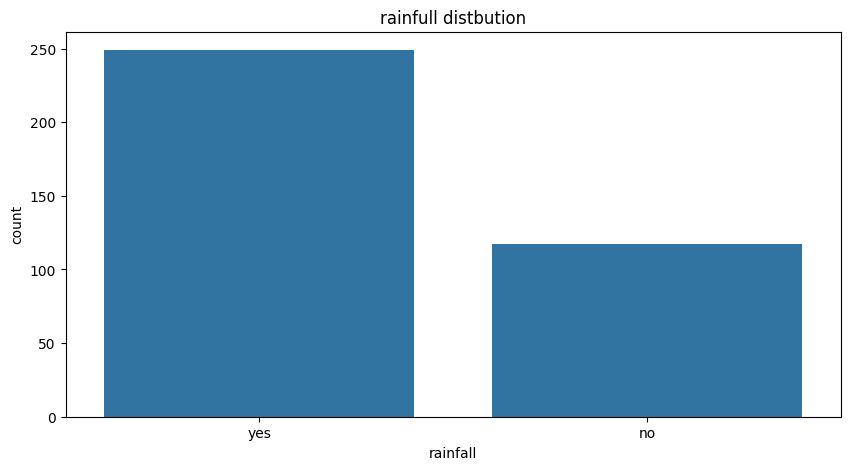

In [ ]:
plt.figure(figsize=(10,5))
sns.countplot(data = df , x = "rainfall")
plt.title("rainfull distbution")
plt.show()
# The classes are moderately imbalanced: rainy days are roughly twice as
# common as dry days in this dataset

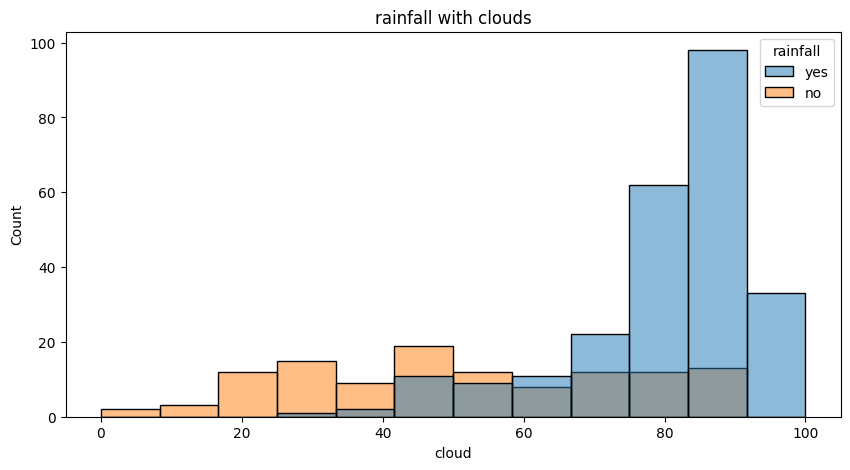

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data = df , hue = "rainfall" , x = "cloud")
plt.title("rainfall with clouds")
plt.show()
#When cloud levels reach 60 or higher, rain occurs
#in other words, the weather becomes rainy as the cloud altitude increases, indicating a direct relationship.

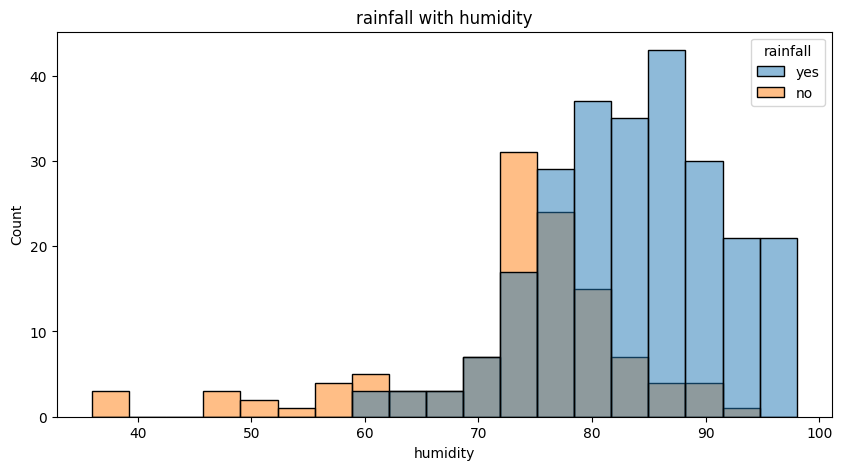

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data = df , hue = "rainfall" , x = "humidity")
plt.title("rainfall with humidity")
plt.show()
#Humidity levels—which fluctuate in direct correlation with temperature—are also linked to rainfall
#when humidity exceeds 75%, the weather is often rainy.

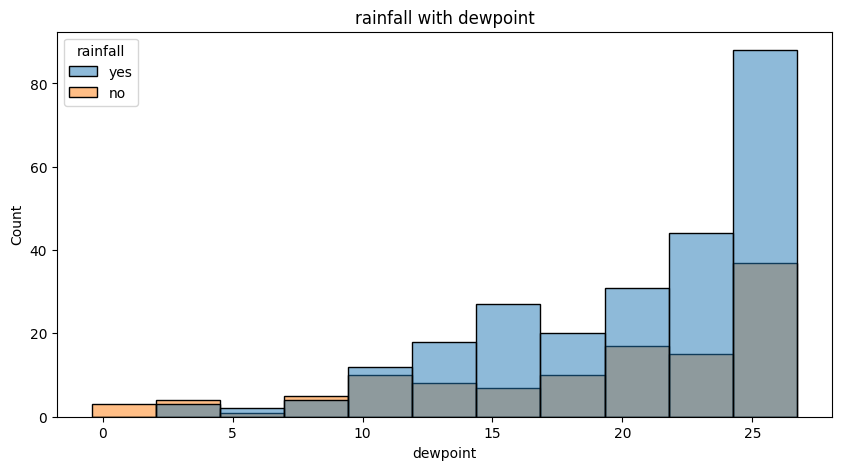

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data = df , hue = "rainfall" , x = "dewpoint")
plt.title("rainfall with dewpoint")
plt.show()
#This measures the actual water content in the air—regardless of temperature changes—specifically, the dew point.
#Also, if the dew point is above 10°C, the weather is often rainy; this means more droplets will form and the air will become more humid.

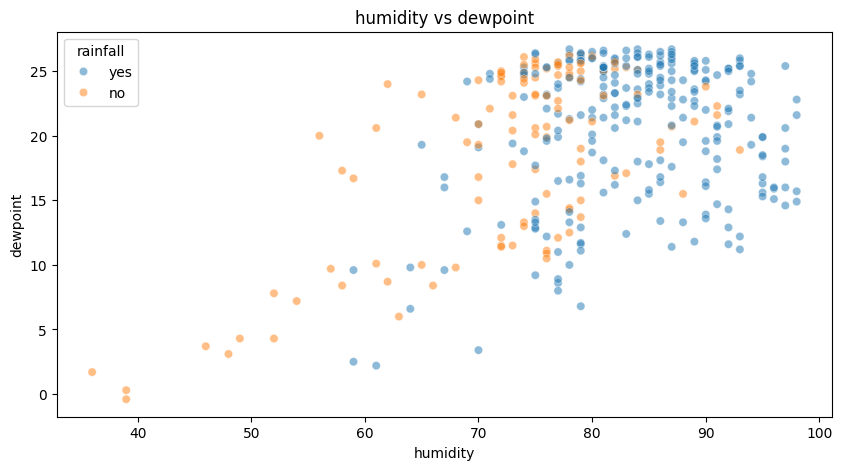

In [ ]:
plt.figure(figsize=(10,5))
sns.scatterplot(data = df , x = "humidity" , y = "dewpoint" , hue = "rainfall" , alpha = 0.5)
plt.title("humidity vs dewpoint")
plt.show()
#There is a direct relationship between them here, which is evident from the two preceding graphs.
#We can observe and anticipate that humidity often has a stronger effect; essentially, as it rises, it leads to rainfall.
#While dew droplets do indeed rise—much like rain—their effect is not always significant; it is generally weaker.

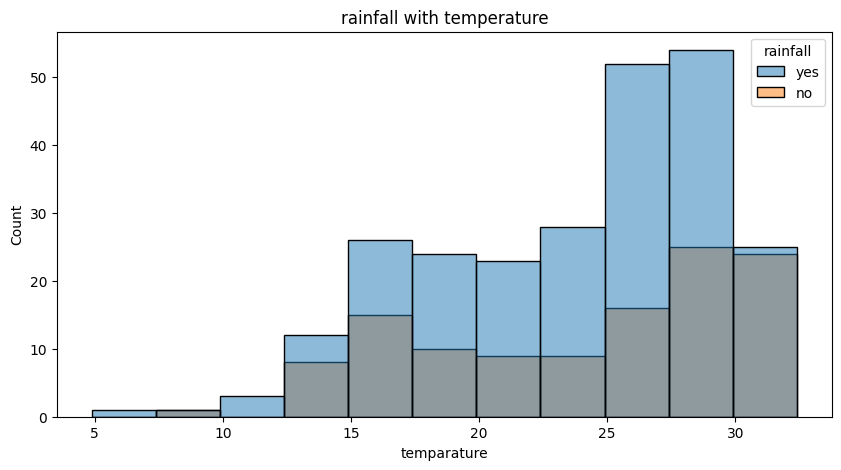

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data = df , hue = "rainfall" , x = "temparature")
plt.title("rainfall with temperature")
plt.show()
#As we expected, the temperature is generally moderate; this area ranges from cool to mild.
#Therefore, rainfall there is abundant; essentially, moderate temperatures contribute to heavy rainfall.
#Low temperatures do not indicate heavy rainfall; on the contrary, the weather tends to be somewhat dry.

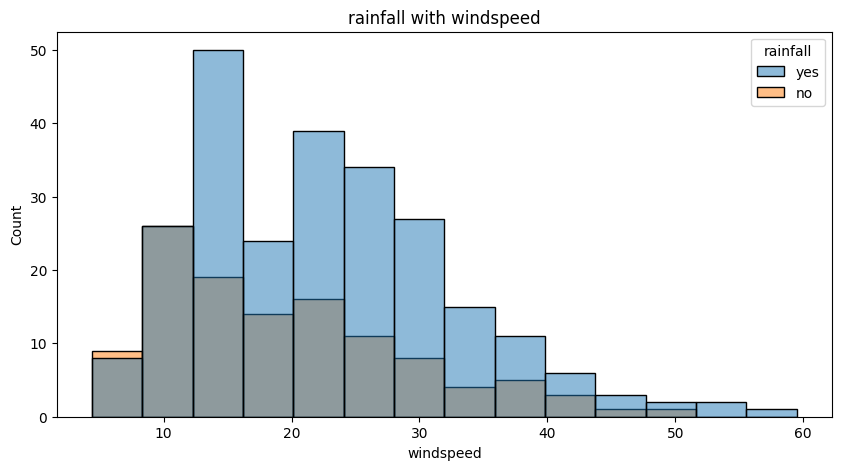

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data = df , x = "windspeed" , hue = "rainfall")
plt.title("rainfall with windspeed")
plt.show()
#Wind speeds in this city are usually around 15, and rainfall is also frequent.

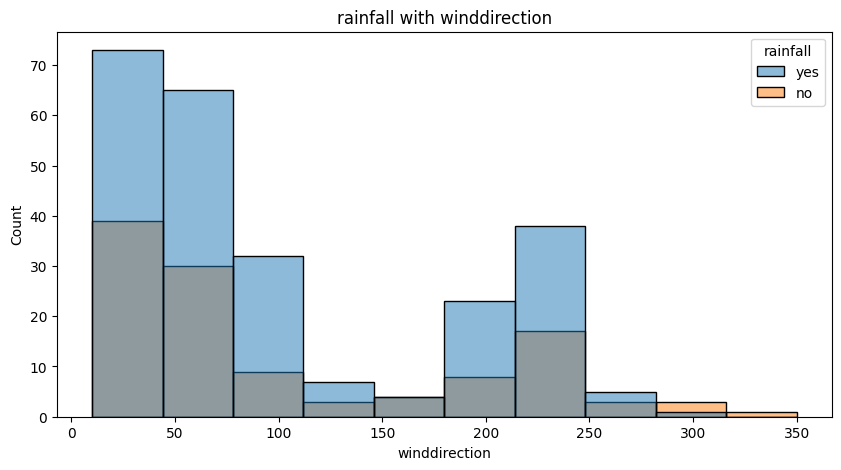

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data = df , x = "winddirection" , hue = "rainfall")
plt.title("rainfall with winddirection")
plt.show()
#Winds generally blow from the northeast or east; they are typically humid and often rain-bearing.
#Winds coming from the west or northwest are usually dry and do not carry rain.
#Similarly, winds from the south and southeast are mostly dry and associated with little rainfall.

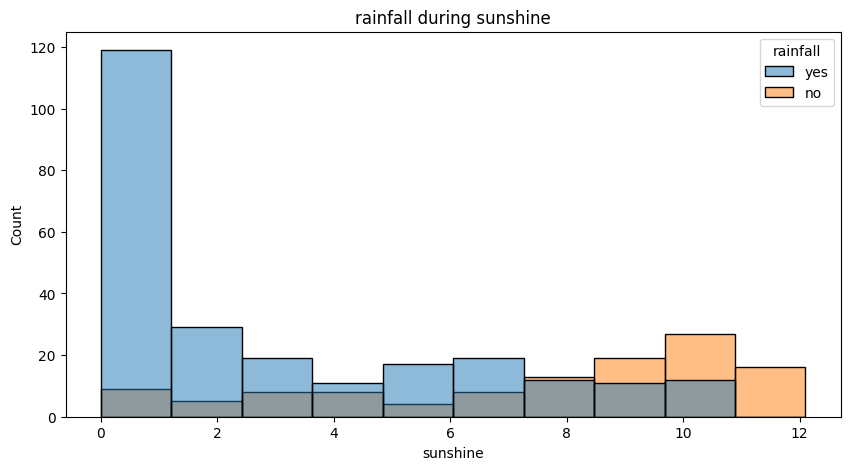

In [ ]:
plt.figure(figsize=(10,5))
sns.histplot(data = df , x = "sunshine" , hue = "rainfall")
plt.title("rainfall during sunshine")
plt.show()
#Generally, the longer the daylight hours, the less rainfall there is; in other words, the relationship is inverse.
#We always notice here that if the sun doesn't come out or the weather is cloudy, it means rain is on the way and it is going to rain.

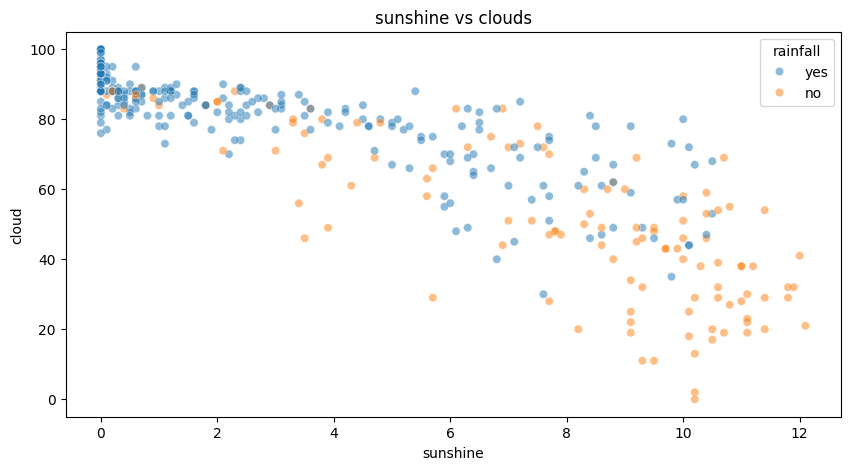

In [ ]:
plt.figure(figsize=(10,5))
sns.scatterplot(data = df , x = "sunshine" , y = "cloud" , hue = "rainfall" , alpha = 0.5)
plt.title("sunshine vs clouds")
plt.show()
#As we expected from the previous graph, there is an inverse relationship between cloud cover and hours of sunshine.
#In other words, as the hours of sunshine decrease,
#cloud cover increases and the weather becomes rainy; conversely, as cloud cover decreases, the hours of sunshine increase.
#also Rainfall has decreased.

<Figure size 1000x500 with 0 Axes>

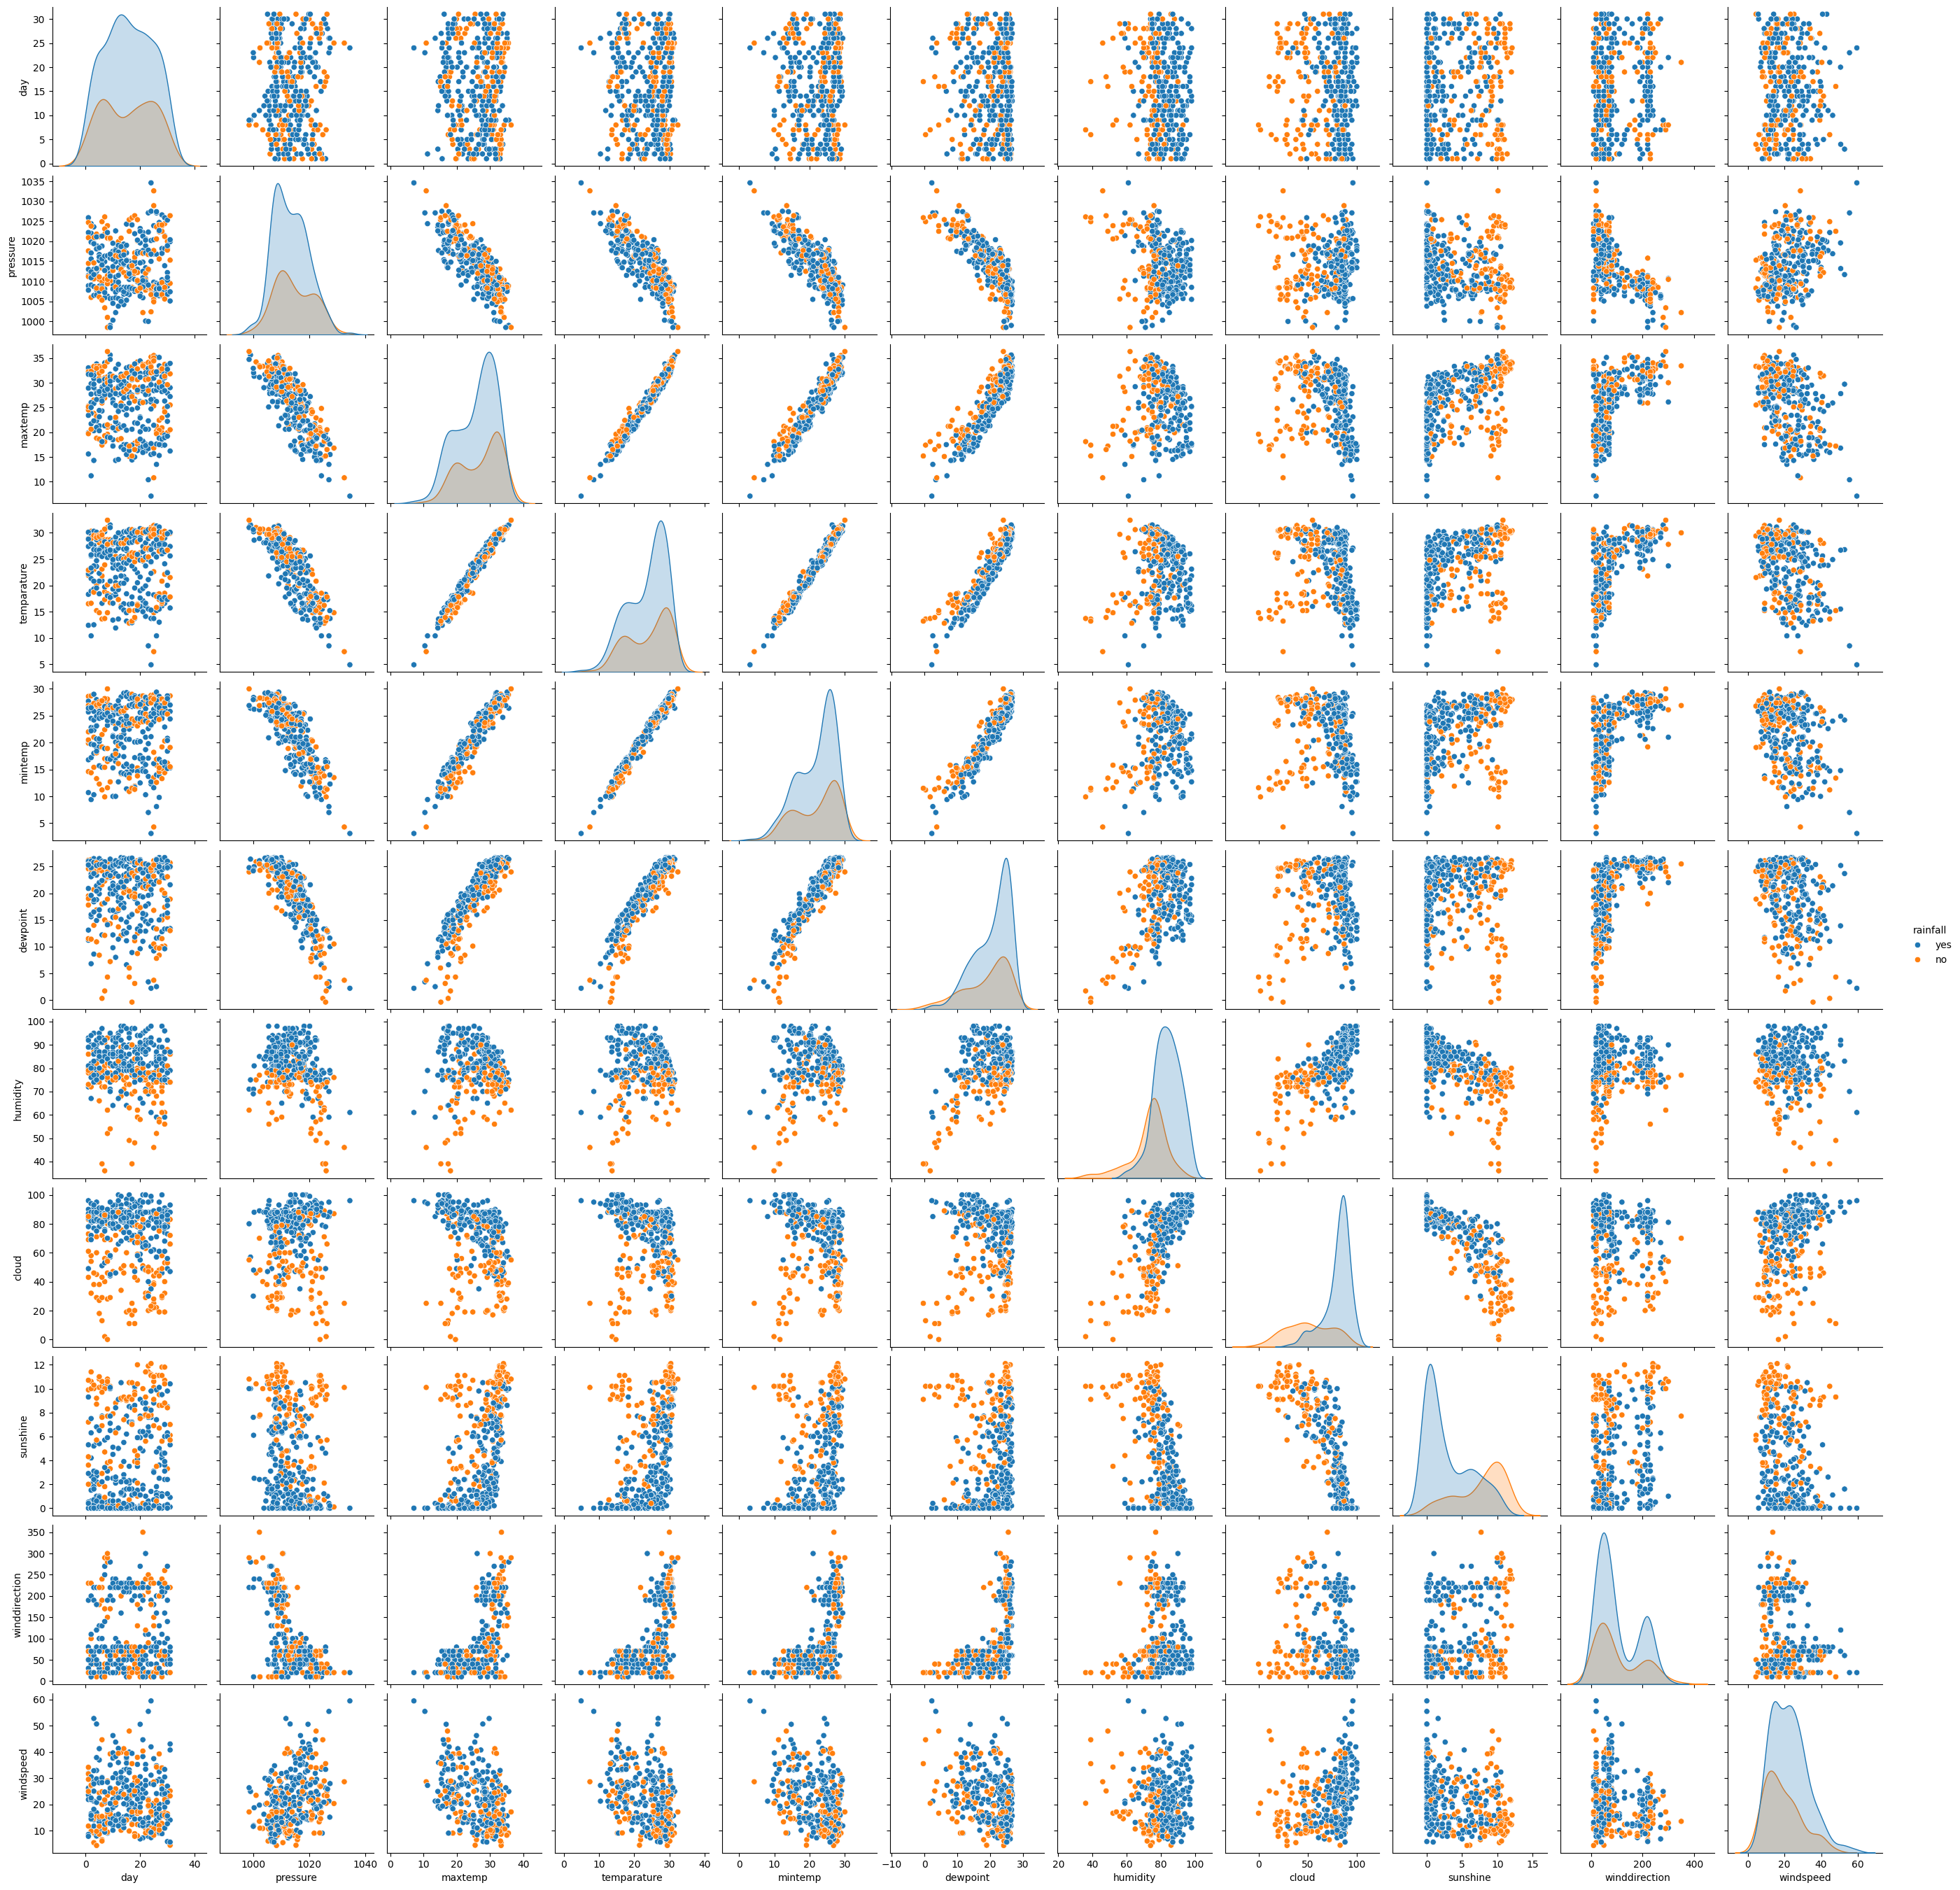

In [ ]:
plt.figure(figsize=(10,5))
sns.pairplot(df , hue= "rainfall")
plt.show()

In [ ]:
correlation = df.corr()
correlation["rainfall"].sort_values(ascending= False)
#The appearance of clouds is certainly the most significant factor, but the humidity level relative to the instantaneous temperature also has a strong impact.
#The number of daylight hours has an inverse—yet very strong—effect on predicting whether or not rainfall will occur.

,rainfall
rainfall,1.000000
cloud,0.625766
humidity,0.489623
windspeed,0.154488
dewpoint,0.139916
day,0.010339
mintemp,-0.007697
winddirection,-0.013214
temparature,-0.037360
pressure,-0.089275


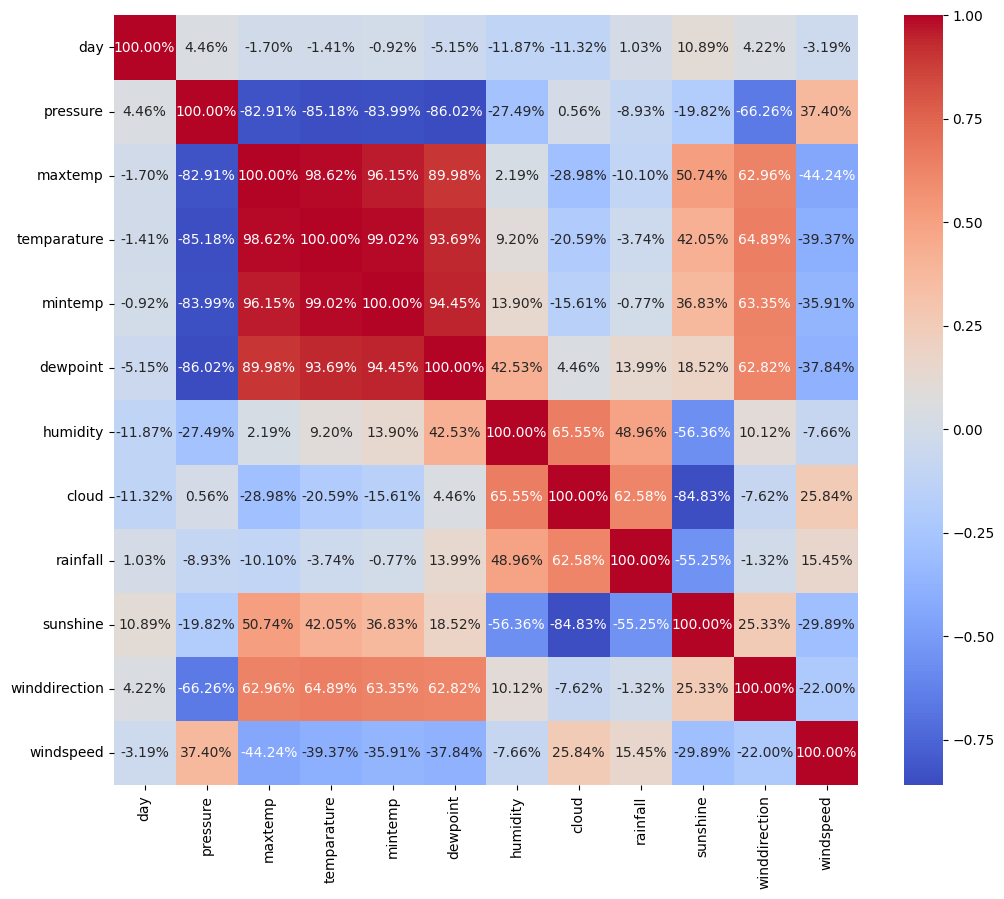

In [ ]:
plt.figure(figsize=(12,10))
sns.heatmap(correlation , annot = True , fmt = ".2%" , cmap = "coolwarm")
plt.show()
#First, we observe the significant impact of wind direction on temperatures; this confirms our earlier point that winds from the north are cold and humid,
#whereas winds from the south are hot and dry.
#Atmospheric pressure also has a strong, inverse relationship with wind direction; furthermore, an increase in pressure inversely affects dew formation,
#thereby reducing the likelihood of rainfall.
#Finally, cloud cover increases alongside humidity—a natural phenomenon.

#Conclusion:

###We observe that cloud cover and regional humidity are the primary indicators of rainfall, carrying more weight than the other data points.

###It is also evident that northerly winds increase atmospheric humidity, thereby significantly raising the likelihood of rainfall.

###Conversely, when sunshine duration exceeds seven hours, the probability of rainfall drops sharply.